# Comparing replay transition kernels

The paper's main analysis studies how decoded position moves from one time bin to the next during a
replay event using a hidden Markov model (HMM):

- the **hidden state** is a position bin on the track;
- the **observations** are the spike counts of every recorded cell in each time bin, Poisson with
  rates fixed from the cells' place fields (they are not learned);
- the **initial state** is uniform over all bins.

Because the observation model and the start are the same for every candidate, candidates differ
only in their **transition kernel**: the matrix of probabilities of moving from one bin to
another in one time bin. Each kernel's free parameters are fitted by EM on training events, and
kernels are compared by the log-likelihood of held-out events (5-fold cross-validation). The kernel with the highest held-out likelihood best describes how replay moves.

This notebook has three parts:

1. **Toy synthetic recovery** Simulate replay events from a known kernel on a toy track, run the
   comparison, and check that the generating kernel wins (about 1 minute).
2. **Use it on your own data.** What each input must look like, how to build the behavioural
   movement matrix, how to read the results, and the mistakes to avoid.
3. **One real session** (optional). Refit one Pfeiffer & Foster (2015) session and check that it
   reproduces the saved fit. It runs only when that session's data and saved fit are present
   (about 1 minute).

**Requirements.** Run from the repository root in the project environment (`environment.yml`),
which installs the modified `ssm` in `third_party/ssm`. Plain `pip install ssm` lacks these
kernels. The code below handles tracks with two linear maps (outbound and inbound runs of one
track), as in the Pfeiffer & Foster and Grosmark & Buzsáki datasets.

## The candidate kernels

Every kernel except momentum has the form

$$A = (1-\varepsilon)\,\big[\kappa I + (1-\kappa)\,A_\text{local}\big] + \varepsilon\,A_\text{jump},$$

where $\kappa$ is the probability of staying in the same bin, $\varepsilon$ the probability of a
jump to any bin ($A_\text{jump}$ is uniform), and $A_\text{local}$ (diagonal set to zero, rows
normalised) carries the structure. $A_\text{local}$ never crosses between the two maps.
$P$ below is the **movement matrix**: bin-to-bin transitions measured from the animal's running.
$M = (I-\gamma P)^{-1}P$ is its successor representation (SR) with discount $\gamma$.

| Kernel (code name) | Label | $A_\text{local}$ | Fitted |
|---|---|---|---|
| `sticky_TCMSR` | TCM-SR | $(1-\omega)M + \omega M^\top M$ | $\kappa, \varepsilon, \gamma, \omega$ |
| `sticky_TCMSR_sym` | Sym. TCM-SR | $M^\top M$ (TCM-SR with $\omega = 1$) | $\kappa, \varepsilon, \gamma$ |
| `sticky_SR` | SR | $M$ | $\kappa, \varepsilon, \gamma$ |
| `sticky_SR_rev` | Rev. SR | $M^\top$: the SR run backwards | $\kappa, \varepsilon, \gamma$ |
| `movement_empirical` | Movement | $P$ itself | $\kappa, \varepsilon$ |
| `continuous_EM` | Continuous | Gaussian step of width $\sigma$ bins | $\kappa, \varepsilon, \sigma$ |
| `momentum` | Momentum | second order: the next bin depends on the last two (damped momentum) | $\lambda_m, \sigma_m$ by grid search |
| `stationary` | Stationary | stays in its bin ($\kappa = 1$) | none |
| `fragmented` | Fragmented | jumps to a uniformly random bin every time bin ($\varepsilon = 1$) | none |

$\varepsilon$ is capped at 0.02 and $\sigma$ at 12 cm, as in the paper.

## Setup

`build_kernels` and `compare_kernels` below are the whole analysis: they make the same calls as
the paper's fits (`replay-hmm fit --dataset pfeiffer|buzsaki`), with the same settings. Copy them
to use the method elsewhere.

In [4]:
import contextlib
import io
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from replay_hmm import paths
from replay_hmm.hmm import constants, cv, fit_session
from replay_hmm.hmm.kernel_sets import KERNEL_ORDER
from replay_hmm.hmm.restore import apply_transition_params_from_summary_row
from replay_hmm.hmm.sampling import sample_state_path_from_P
from replay_hmm.hmm.two_map_kernels import build_two_map_hmm_dict
from replay_hmm.hmm.two_map_movement import count_movement_P
from replay_hmm.plots.labels import KERNEL_COLORS, kernel_label
from replay_hmm.plots.style import apply_analysis_plot_style

apply_analysis_plot_style()
N_JOBS = min(4, os.cpu_count() or 1)  # parallel EM workers


def build_kernels(rate_maps_hz, movement_P, *, dt, bin_width_cm, kernels=KERNEL_ORDER):
    # One ssm HMM per kernel (momentum is the package's own order-2 model), all sharing the same
    # fixed Poisson observations: rate_maps_hz * dt spikes per bin.
    n_bins = rate_maps_hz.shape[1] // 2
    return build_two_map_hmm_dict(
        lin_map_concat_hmm=rate_maps_hz,
        lin_map_bounds_hmm=np.array([0, n_bins, 2 * n_bins]),
        movement_P=movement_P,
        kernels=tuple(kernels),
        decode_tbin_s=dt,
        eps_cap=constants.EPS_CAP,
        eps_init=constants.EPS_INIT,
        sigma_cap=constants.sigma_cap_bins_from_cm(constants.SIGMA_CAP_CM, bin_width_cm),
        sigma_init=constants.sigma_cap_bins_from_cm(constants.SIGMA_INIT_CM, bin_width_cm),
        bin_width_cm=bin_width_cm,
    )



def compare_kernels(hmm_dict, events, *, n_jobs=N_JOBS):
    # 5-fold CV and a full-data fit for every kernel, with the paper's EM settings.
    # Returns the per-kernel CV summary, the BIC table and the full-data fits.

    cv_df, fit_df = cv.parallel_fit_over_models_joblib(
        hmm_dict=hmm_dict,
        datas_mb=events,
        split_seed=fit_session.SPLIT_SEED,
        k_folds=fit_session.K_FOLDS,
        num_em_iters=fit_session.NUM_EM_ITERS,
        em_tol=fit_session.EM_TOL,
        em_tol_per_bin=fit_session.EM_TOL_PER_BIN,
        mstep_lr=fit_session.MSTEP_LR,
        mstep_steps=fit_session.MSTEP_STEPS,
        mstep_clip=fit_session.MSTEP_CLIP,
        n_jobs=n_jobs,
    )
    summary = cv.summarize_cv(cv_df).set_index("model")
    summary["deficit_per_bin"] = summary["val_ll_per_bin"].max() - summary["val_ll_per_bin"]
    bic = cv.bic_table(fit_df).set_index("model")
    return summary, bic, fit_df.set_index("model")


def results_table(summary, bic):
    out = pd.DataFrame({
        "held-out LL / bin": summary["val_ll_per_bin"],
        "deficit / bin": summary["deficit_per_bin"],
        "deficit (nats)": summary["dLL_val"] - 1.0,
        "ΔBIC": bic.loc[summary.index, "dBIC"] - 1.0,
    })
    out.index = [kernel_label(k) for k in summary.index]
    return out.sort_values("deficit (nats)").round(3)


def plot_deficit(summary, title, ax):
    order = [k for k in KERNEL_ORDER if k in summary.index]
    y = np.arange(len(order))
    ax.barh(y, summary.loc[order, "dLL_val"], color=[KERNEL_COLORS[k] for k in order])
    ax.set_xscale("log")
    ax.set_yticks(y, [kernel_label(k) for k in order])
    ax.invert_yaxis()
    ax.set_xlabel(r"$\Delta$NLL deficit from best + 1 (nats)")
    ax.set_title(title)

---
# Part 1: Toy demonstration of model comparison and recovery

Two maps of 15 bins at 4 cm (a 60 cm track run in both directions) and 30 cells with Gaussian
place fields, drawn independently on each map so that the two running directions are
distinguishable. Replay is decoded in 10 ms bins, as in the paper.

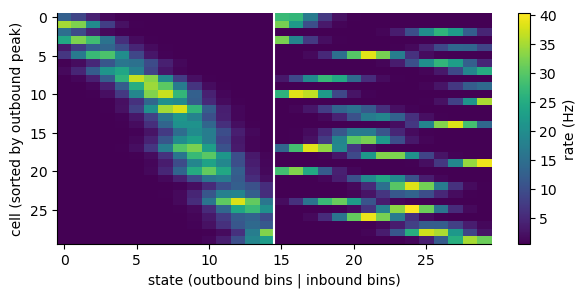

In [5]:
BIN_CM, DT, N_BINS, N_CELLS = 4.0, 0.01, 15, 30
K = 2 * N_BINS
rng = np.random.default_rng(0)

x = np.arange(N_BINS)
rate_maps_hz = np.zeros((N_CELLS, K))
for m in range(2):  # map 0 = outbound, map 1 = inbound
    for c in range(N_CELLS):
        centre = rng.uniform(-1, N_BINS)
        peak = 40.0 * rng.uniform(0.3, 1.0)
        rate_maps_hz[c, m * N_BINS:(m + 1) * N_BINS] = peak * np.exp(-0.5 * ((x - centre) / 1.5) ** 2)
rate_maps_hz += 0.5  # background rate

order = np.argsort(rate_maps_hz[:, :N_BINS].argmax(1))
fig, ax = plt.subplots(figsize=(7, 3))
im = ax.imshow(rate_maps_hz[order], aspect="auto", cmap="viridis")
ax.axvline(N_BINS - 0.5, color="w")
ax.set(xlabel="state (outbound bins | inbound bins)", ylabel="cell (sorted by outbound peak)")
fig.colorbar(im, label="rate (Hz)")
plt.show()

## The movement matrix from behaviour

The SR, TCM-SR and movement kernels are built from $P$, the animal's own bin-to-bin transitions
while running. Here we simulate 30 laps at 15–35 cm/s, sampled every 100 ms, and count
transitions with `count_movement_P`, the function the paper's two-map datasets use. Samples
slower than 5 cm/s are excluded, and each direction of running fills its own map's block, so $P$
is block-diagonal.

1379 transition pairs, 3 dropped at turnarounds, 0 unvisited bins


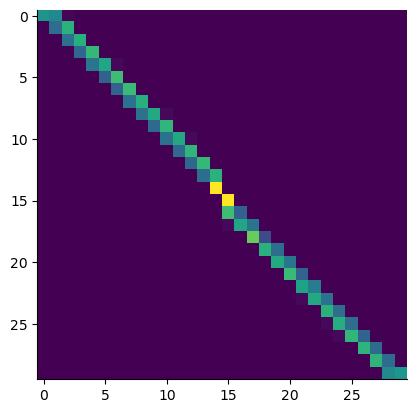

In [6]:
track_cm = N_BINS * BIN_CM
pos = []
for lap in range(30):
    speed = rng.uniform(15, 35)
    run = np.linspace(0, track_cm - 1e-6, int(track_cm / speed / 0.1))
    pos += list(run) + [track_cm - 1e-6] * 10 + list(run[::-1]) + [0.0] * 10  # out, pause, back, pause
pos = np.clip(np.array(pos) + rng.normal(0, 0.5, len(pos)), 0, track_cm - 1e-6)
velocity = np.gradient(pos) / 0.1  # cm/s

movement_P, n_pairs, n_turnaround, n_unvisited = count_movement_P(
    pos_bin=(pos // BIN_CM).astype(int),
    n_bins=N_BINS,
    valid=np.abs(velocity) > 5.0,  # running samples only
    outbound=velocity > 0,
    inbound=velocity < 0,
    selections=[np.arange(len(pos))],  # one continuous recording; consecutive samples pair up
)
print(f"{n_pairs} transition pairs, {n_turnaround} dropped at turnarounds, {n_unvisited} unvisited bins")

plt.imshow(movement_P)

## Two generators

We simulate events from two kernels with different structure: **TCM-SR**, which follows the
behavioural movement statistics, and **Continuous**, which takes Gaussian steps with no
knowledge of behaviour. Each generator is a kernel built with `build_kernels`, its parameters set
by hand.

In the TCM-SR matrix, the bright column on each map is the bin where every run ends (outbound
bin 14, inbound bin 0): the successor representation weighs where the animal will be, and every
run finishes there.

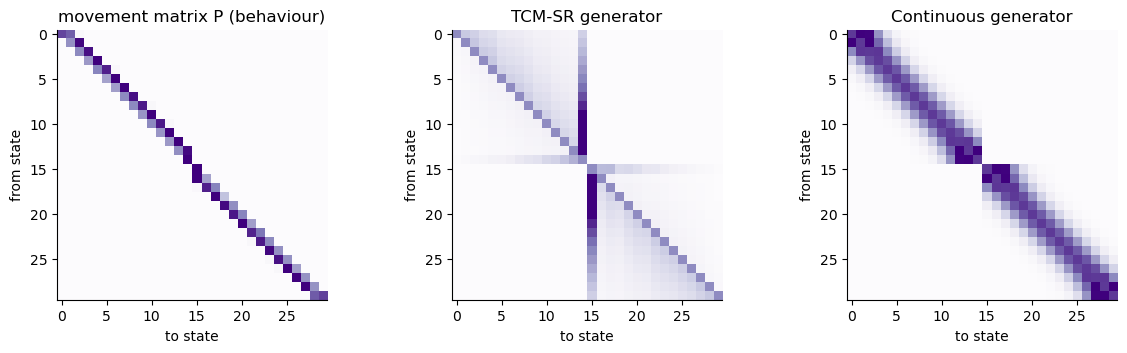

In [7]:
GENERATOR_PARAMS = {
    "sticky_TCMSR": {"kappa": 0.2, "gamma": 0.9, "omega": 0.1, "eps": 0.005},
    "continuous_EM": {"kappa": 0.2, "sigma_arm": 2.0, "eps": 0.005},
}
generators = build_kernels(rate_maps_hz, movement_P, dt=DT, bin_width_cm=BIN_CM,
                           kernels=GENERATOR_PARAMS)
for name, params in GENERATOR_PARAMS.items():
    apply_transition_params_from_summary_row(generators[name], params)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [("movement matrix P (behaviour)", movement_P)] + [
    (f"{kernel_label(k)} generator", generators[k].transitions.transition_matrix) for k in generators
]
for ax, (title, A) in zip(axes, panels):
    ax.imshow(A, cmap="Purples", vmax=np.quantile(A, 0.99))
    ax.set(title=title, xlabel="to state", ylabel="from state")
plt.tight_layout()
plt.show()

## Simulated replay events

Each event is a state path drawn from the generator (start uniform over all bins), and spike
counts drawn from the place fields along it: Poisson with mean rate × 10 ms. Events last 8–19
bins (80–190 ms). The model sees only the counts.

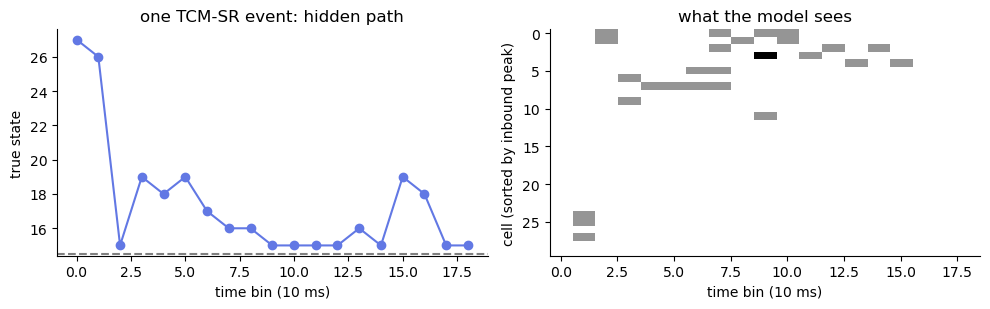

In [8]:
def simulate_events(generator, n_events, rng):
    A = generator.transitions.transition_matrix
    expected_counts = rate_maps_hz * DT  # (cells, states): mean spikes per 10 ms bin
    paths, events = [], []
    for T in rng.integers(8, 20, size=n_events):
        z = sample_state_path_from_P(A, int(T), rng)
        paths.append(z)
        events.append(rng.poisson(expected_counts[:, z].T).astype(np.int32))  # (T, cells)
    return paths, events

simulated = {name: simulate_events(gen, 80, np.random.default_rng(seed))
             for seed, (name, gen) in enumerate(generators.items(), start=1)}

paths_, events_ = simulated["sticky_TCMSR"]
i = int(np.argmax([len(p) for p in paths_]))
event_map = int(paths_[i][0] >= N_BINS)  # 0 = outbound, 1 = inbound
map_order = np.argsort(rate_maps_hz[:, event_map * N_BINS:(event_map + 1) * N_BINS].argmax(1))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 3.2))
a0.plot(paths_[i], "o-")
a0.axhline(N_BINS - 0.5, color="grey", ls="--")
a0.set(xlabel="time bin (10 ms)", ylabel="true state", title="one TCM-SR event: hidden path")
a1.imshow(events_[i].T[map_order], aspect="auto", cmap="Greys")
a1.set(xlabel="time bin (10 ms)", ylabel=f"cell (sorted by {['outbound', 'inbound'][event_map]} peak)",
       title="what the model sees")
plt.tight_layout()
plt.show()

## Run the comparison

All nine kernels are fitted to each simulated event set: 5 folds plus one full-data fit per
kernel, 200 EM iterations at most, exactly as for the paper's sessions.

In [9]:
results = {}
for name, (_, events) in simulated.items():
    results[name] = compare_kernels(build_kernels(rate_maps_hz, movement_P, dt=DT, bin_width_cm=BIN_CM), events)
    winner = results[name][0]["val_loglik"].idxmax()
    print(f"generated by {kernel_label(name):<11} -> best held-out kernel: {kernel_label(winner)}")

generated by TCM-SR      -> best held-out kernel: TCM-SR


generated by Continuous  -> best held-out kernel: Continuous


In [10]:
summary, bic, fits = results["sticky_TCMSR"]
results_table(summary, bic)

,held-out LL / bin,deficit / bin,deficit (nats),ΔBIC
TCM-SR,-6.478,0.000,0.000,0.000
Sym. TCM-SR,-6.491,0.012,13.144,20.531
SR,-6.521,0.042,45.356,87.523
Momentum,-6.655,0.177,189.998,364.186
Continuous,-6.678,0.200,214.886,429.489
Fragmented,-6.823,0.345,370.509,722.293
Movement,-6.885,0.406,436.739,863.153
Rev. SR,-7.011,0.532,572.356,1138.007
Stationary,-7.654,1.175,1263.398,2508.071


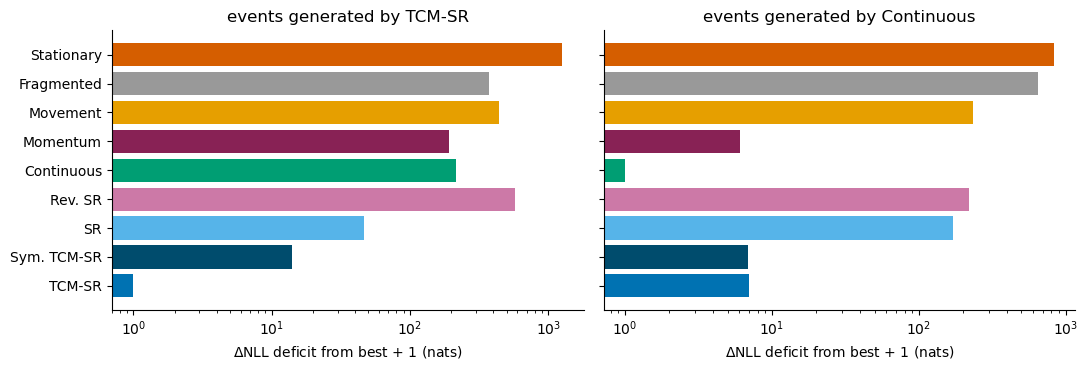

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, (summary, _, _)) in zip(axes, results.items()):
    plot_deficit(summary, f"events generated by {kernel_label(name)}", ax)
plt.tight_layout()
plt.show()

The heatmap puts both runs side by side: each row is a generator, each column a fitted kernel,
and each cell the held-out log-likelihood deficit per time bin relative to that row's best
kernel (0 = best).

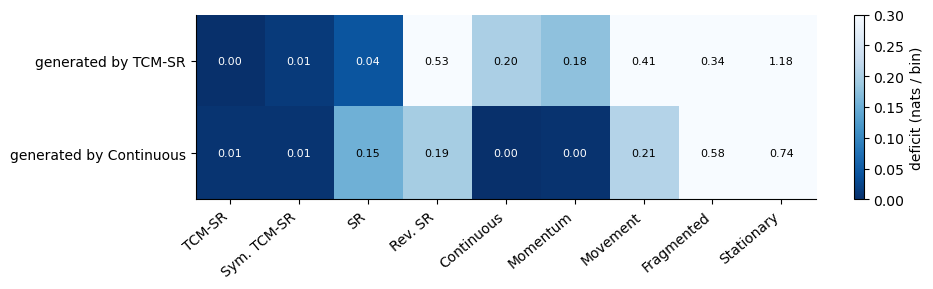

In [12]:
deficit = pd.DataFrame({kernel_label(name): res[0]["deficit_per_bin"] for name, res in results.items()}).T
deficit = deficit[[k for k in KERNEL_ORDER]].rename(columns=kernel_label)
fig, ax = plt.subplots(figsize=(10, 2.4))
im = ax.imshow(deficit.values, cmap="Blues_r", aspect="auto", vmax=0.3)
ax.set_xticks(range(deficit.shape[1]), deficit.columns, rotation=40, ha="right")
ax.set_yticks(range(deficit.shape[0]), [f"generated by {g}" for g in deficit.index])
for (r, c), v in np.ndenumerate(deficit.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="k" if v > 0.15 else "w")
fig.colorbar(im, label="deficit (nats / bin)")
plt.show()

## Are the generating parameters recovered?

The full-data fit of each generating kernel, next to the values it was simulated with.

In [13]:
rows = []
for name, params in GENERATOR_PARAMS.items():
    fitted = results[name][2].loc[name]
    for p, true in params.items():
        rows.append({"generator": kernel_label(name), "parameter": p, "true": true, "fitted": float(fitted[p])})
pd.DataFrame(rows).round(3)

,generator,parameter,true,fitted
0,TCM-SR,kappa,0.200,0.223
1,TCM-SR,gamma,0.900,0.905
2,TCM-SR,omega,0.100,0.085
3,TCM-SR,eps,0.005,0.005
4,Continuous,kappa,0.200,0.176
5,Continuous,sigma_arm,2.000,1.857
6,Continuous,eps,0.005,0.003


- Both generators are recovered, and the kernels that ignore movement structure (stationary,
  fragmented) or follow the wrong structure fall far behind.
- Nested siblings sit close together: TCM-SR and Sym. TCM-SR differ only in $\omega$, and
  Continuous and Momentum agree on the step-size distribution and differ only in whether steps
  are correlated. On a small event set they can trade places. With $\omega = 0.5$ instead of
  0.1, for example, this toy set does not pin $\omega$ down and Sym. TCM-SR ties with TCM-SR.
  That is why the paper reads families (TCM-SR + Sym. TCM-SR, Continuous + Momentum) as well as
  single kernels.
- $\kappa$, $\gamma$, $\omega$ and $\sigma$ come back close to their true values. $\varepsilon$ is
  small and the least well determined: jumps are rare, so few events carry information about it.

---
# Part 2: use it on your own data

## Inputs

| Input | Shape | Units and layout |
|---|---|---|
| `events` | list of `(T_i, n_cells)` arrays | integer spike counts per time bin of width `dt`, one array per replay event; cells in the same order as the rate maps |
| `rate_maps_hz` | `(n_cells, 2n)` | firing rate in **Hz** (not counts per bin), outbound bins `0..n-1` then inbound bins `n..2n-1` |
| `movement_P` | `(2n, 2n)` | row-stochastic, block-diagonal: outbound-to-outbound and inbound-to-inbound only |
| `dt` | scalar | decode bin width in seconds (the paper uses 0.01) |
| `bin_width_cm` | scalar | spatial bin width; momentum and the $\sigma$ cap are in physical units |

Notes:

- Both maps are indexed by position: inbound bin $i$ is the same place on the track as
  outbound bin $i$, so forward running moves up the bin indices on the outbound map and down
  them on the inbound map. `count_movement_P` fills both blocks this way, and the rate maps must
  use the same layout.
- The paper's events are the stretches of each candidate event where the memoryless decoder puts
  most of its posterior on one map (`datasets/two_map_event_sets.py`). Any segmentation works,
  but every event needs at least 2 bins, and there must be at least 2 events (the number of folds
  is `min(5, n_events)`).
- To build `movement_P` from your own tracking, pass `count_movement_P` the position bin of each
  sample, a validity mask (the paper keeps samples above 5 cm/s), outbound and inbound labels,
  and the runs of sample indices to pair. The paper pairs samples 100 ms apart within each
  behavioural epoch; see `datasets/pfeiffer/movement.py` for a complete example. Bins never
  visited while running get a uniform row, and `count_movement_P` prints how many there are.

`check_inputs` catches the common mistakes before a long fit:

In [14]:
def check_inputs(events, rate_maps_hz, movement_P, dt):
    problems = []
    n_cells, K = rate_maps_hz.shape
    n = K // 2
    if K % 2:
        problems.append(f"rate maps have {K} states; two maps of equal length are expected")
    if movement_P.shape != (K, K) or not np.allclose(movement_P.sum(1), 1):
        problems.append("movement_P must be (K, K) with rows summing to 1")
    elif movement_P[:n, n:].any() or movement_P[n:, :n].any():
        uniform = np.isclose(movement_P, 1 / K).all(1)
        problems.append(f"movement_P crosses between maps ({uniform.sum()} rows are the uniform "
                        "fill for unvisited bins; other rows are a layout error)")
    if any(e.ndim != 2 or e.shape[1] != n_cells for e in events):
        problems.append(f"every event must be (time bins, {n_cells} cells)")
    if any(not np.issubdtype(e.dtype, np.integer) for e in events):
        problems.append("spike counts must be integers")
    if len(events) < 2 or min(len(e) for e in events) < 2:
        problems.append("need at least 2 events of at least 2 bins each")
    if np.nanmax(rate_maps_hz) < 2:
        problems.append("rate maps peak below 2 Hz: are they counts per bin rather than Hz?")
    observed = np.concatenate(events).mean()
    expected = np.nanmean(rate_maps_hz) * dt
    if not 0.2 < observed / expected < 5:
        problems.append(f"events have {observed / expected:.1f}x the spikes the rate maps predict "
                        "at this dt: check dt, units and cell order")
    silent = (np.nan_to_num(rate_maps_hz) <= 0).all(0)
    if silent.any():
        problems.append(f"{silent.sum()} bins where no cell fires: the decoder cannot see them")
    return problems or ["inputs look consistent"]


print("Part 1 inputs:", check_inputs(simulated["sticky_TCMSR"][1], rate_maps_hz, movement_P, DT))
print("rates passed as counts per bin:", check_inputs(simulated["sticky_TCMSR"][1], rate_maps_hz * DT, movement_P, DT))

Part 1 inputs: ['inputs look consistent']
rates passed as counts per bin: ['rate maps peak below 2 Hz: are they counts per bin rather than Hz?', 'events have 98.7x the spikes the rate maps predict at this dt: check dt, units and cell order']


Then, with your own arrays:

```python
hmm_dict = build_kernels(rate_maps_hz, movement_P, dt=0.01, bin_width_cm=4.0)
summary, bic, fits = compare_kernels(hmm_dict, events)
results_table(summary, bic)
```

## Reading the results

- **Held-out LL / bin** is the cross-validated log-likelihood per time bin, summed over the five
  held-out folds. Differences between kernels are what matter; the absolute value depends on
  the number of cells and their rates.
- **Deficit (nats)** is the best kernel's held-out log-likelihood minus this kernel's, over all
  held-out bins. The paper's strip plots show deficit + 1 on a log axis, so the best kernel sits
  at 1. **Deficit / bin** is the same gap per held-out time bin, which compares across event sets
  of different sizes.
- **ΔBIC** uses the full-data fit, charging $\log(\text{transitions})$ per fitted parameter.
  Cross-validation and BIC usually agree. When they disagree, the difference is usually between
  nested siblings and is small, and cross-validation is the paper's primary criterion.
- **Fitted parameters** are in `fits` (one row per kernel): `kappa` (stay probability), `eps`
  (jump probability), `gamma` (SR horizon), `omega` (weight of the $M^\top M$ term),
  `sigma_arm` (continuous step width in bins), and for momentum `lambda_m` (1/s) and `sigma_m`
  (cm/s$^{1.5}$). Columns ending in `_at_cap` / `_at_min` flag a parameter at its bound; a
  parameter there was limited by the bound, not by the data.

## Things that go wrong

- **Kernel names are part of the fit.** `cv` configures each model by its dictionary key
  (`stationary`, `fragmented` and `momentum` are held fixed or grid-searched, and markers set by
  the builder pin $\omega$ for Sym. TCM-SR). Keep the names `build_kernels` returns; don't
  rename them.
- **Momentum is not an ssm HMM.** It has its own order-2 forward-backward and is fitted by grid
  search, so it has no `K × K` transition matrix, and it needs `bin_width_cm`.
- **Parallel workers.** `n_jobs > 1` starts worker processes that re-import the package.
- **More than two maps.** `build_kernels` handles one track run in two directions. The paper's
  multi-arm maze (Lustig) uses its own builder, `datasets/lustig/kernels.py`.

---
# Part 3 (optional): one real session

Pfeiffer & Foster (2015), Rat 1, Linear4: the smallest session in the paper (25 events, 158
cells, 90 states at 4 cm). This refits it from its raw data and the inputs its saved fit
recorded, with the same `build_kernels` and `compare_kernels` as above, and compares the result
with the saved fit. It needs `data/PfeifferFoster2015/Rat1/Linear4` and the saved fit under
`results/`; without them it stops here.

In [15]:
from replay_hmm.datasets import two_map_event_sets
from replay_hmm.datasets.pfeiffer import rebuild as pfeiffer_rebuild
from replay_hmm.datasets.pfeiffer.session import PFEIFFER_DECODED_VIEW
from replay_hmm.hmm.rebuild_two_map import load_inputs
from replay_hmm.io.fit_summary import load_saved_fit_summary

RAT, SESSION = "Rat1", "Linear4"
DATA_DIR = paths.PFEIFFER_DATA_DIR / RAT / SESSION
FIT_DIR = paths.PFEIFFER_FITS_DIR / RAT / SESSION / "dtbin_0p01__step_0p01__hmmbin_4__evt_spikedens"
RUN_REAL_SESSION = DATA_DIR.is_dir() and (FIT_DIR / "full_fit_summary_full_em_mbtraj.json").is_file()
if not RUN_REAL_SESSION:
    print(f"Skipping Part 3: needs {DATA_DIR} and the saved fit in {FIT_DIR}.")

In [16]:
if RUN_REAL_SESSION:
    saved_summary, _ = load_saved_fit_summary(FIT_DIR / "full_fit_summary_full_em_mbtraj.json")
    saved_inputs = load_inputs(FIT_DIR / "pfeiffer_hmm_mbtraj_inputs.npz", saved_summary, f"{RAT}/{SESSION}")
    # Re-detect and decode the session's events on the saved maps, then cut them into
    # single-map trajectory stretches: the fit's own event set.
    rebuilt = pfeiffer_rebuild.rebuild_events(RAT, SESSION, saved_summary, saved_inputs, label=f"{RAT}/{SESSION}")
    real_events = two_map_event_sets.collect_mb_traj_datas(rebuilt.decoded, PFEIFFER_DECODED_VIEW, min_len=2)
    real_rates_hz, real_P = saved_inputs["lin_map_concat"], saved_inputs["movement_P"]
    real_dt, real_bin_cm = float(saved_summary["decode_tbin_s"]), float(saved_summary["hmm_bin_width_cm"])

    print(f"events: {len(real_events)} arrays, shapes {real_events[0].shape} ... dtype {real_events[0].dtype}")
    print(f"rate maps: {real_rates_hz.shape} Hz, movement_P: {real_P.shape}, dt = {real_dt} s, bins = {real_bin_cm} cm")
    print(check_inputs(real_events, real_rates_hz, real_P, real_dt))

events: 25 arrays, shapes (8, 158) ... dtype int32
rate maps: (158, 90) Hz, movement_P: (90, 90), dt = 0.01 s, bins = 4.0 cm
['inputs look consistent']


In [17]:
if RUN_REAL_SESSION:
    real_summary, real_bic, real_fits = compare_kernels(
        build_kernels(real_rates_hz, real_P, dt=real_dt, bin_width_cm=real_bin_cm), real_events)
    saved_cv = pd.read_csv(FIT_DIR / "cv_model_summary_full_em_mbtraj.csv").set_index("model")
    check = pd.DataFrame({
        "refit held-out LL": real_summary["val_loglik"],
        "saved held-out LL": saved_cv.loc[real_summary.index, "val_loglik"],
    })
    check["relative difference"] = ((check.iloc[:, 0] - check.iloc[:, 1]) / check.iloc[:, 1]).abs()
    print(f"best kernel: refit {kernel_label(real_summary['val_loglik'].idxmax())}, "
          f"saved {kernel_label(saved_cv.loc[real_summary.index, 'val_loglik'].idxmax())}")
    display(check.rename(index=kernel_label).sort_values("refit held-out LL", ascending=False))

best kernel: refit Sym. TCM-SR, saved Sym. TCM-SR


,refit held-out LL,saved held-out LL,relative difference
model,,,
Sym. TCM-SR,-5164.413146,-5164.413146,0.000000e+00
Momentum,-5165.035338,-5165.035338,0.000000e+00
TCM-SR,-5166.630844,-5166.630844,0.000000e+00
Continuous,-5180.626923,-5180.626923,0.000000e+00
SR,-5182.951601,-5182.951601,0.000000e+00
Movement,-5190.905320,-5190.905320,0.000000e+00
Rev. SR,-5198.873091,-5198.873091,6.997630e-16
Stationary,-5349.149980,-5349.149980,0.000000e+00
Fragmented,-5520.313510,-5520.313510,0.000000e+00


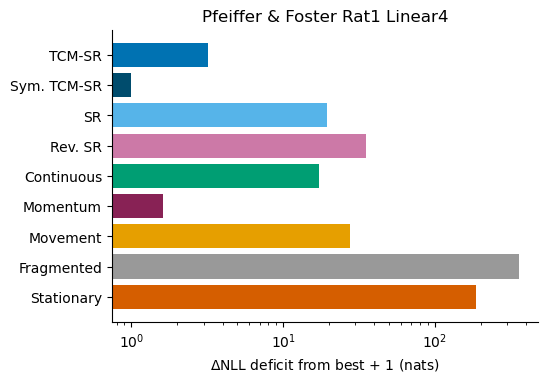

In [18]:
if RUN_REAL_SESSION:
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    plot_deficit(real_summary, f"Pfeiffer & Foster {RAT} {SESSION}", ax)
    plt.show()

On this session, the refit matches the saved fit's held-out log-likelihoods to rounding error,
and Sym. TCM-SR, Momentum and TCM-SR lead within a few nats of one another. One session with 25
events cannot separate them; the paper's conclusions pool every session of the three datasets.